# Figure 5: double-descent peak on Pile token statistics

Final camera-ready version. The figure is drawn from `data/peak_location_results.npz`, the output of the peak-location experiment `DoubleDescentPeak-Sparsity-pile.ipynb` (rerun on 6 Nov 2026, Colab CPU runtime; Pythia tokenizer on a 10,000-document sample of the Pile, top 4000 types, one token per sample, $\alpha_2=0.3$, linear random features, minimum-norm least squares, 4 seeds). Nothing is recomputed here. The cell below recomputes the peak locations from the stored loss curves: $D=1231$ (sparse) and $610$ (dense) at $N=600$, $D=3046$ and $1160$ at $N=1200$, against $K(D)=N$ at $D=1208$ and $3184$.

The figure shows $N=1200$ and is drawn at its printed size, $2.75\times1.9$ in (`0.5\textwidth`), with the settings of Figure 2: tick labels 7 pt, axis labels 8 pt, legend and in-plot labels 7 pt.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.transforms as mtransforms

plt.rcParams.update({"font.family": "DejaVu Sans",
                     "mathtext.fontset": "dejavusans",
                     "pdf.fonttype": 42})

# Printed sizes (pt); the figure is drawn at its size on the page
FIG_W, FIG_H = 2.75, 1.9          # inches; 0.5\textwidth in the NeurIPS template
FS_TICK, FS_LABEL, FS_LEGEND = 7, 8, 7

PEAK = "data/peak_location_results.npz"

In [2]:
# Peak locations, recomputed from the stored loss curves (same rule as the experiment notebook)
z = np.load(PEAK)
Dgrid, K_meas = z["Dgrid"].astype(float), z["K_meas"]
Kinv = lambda k: float(np.exp(np.interp(np.log(k), np.log(K_meas), np.log(Dgrid))))   # D at which K(D) = k

def find_peak(D, L):
    """Local maximum relative to neighbours, interior points only."""
    q = L[1:-1] / np.maximum(L[:-2], L[2:])
    return int(D[1:-1][int(np.argmax(q))]), float(q.max())

print(f"{'N':>6}{'design':>8}{'peak D':>8}{'prediction':>12}{'peak/pred':>11}")
for N in z["N_LIST"]:
    for tag, pred in (("sparse", Kinv(N)), ("dense", float(N))):
        pk, _ = find_peak(z[f"{N}_{tag}_D"], z[f"{N}_{tag}_L"])
        print(f"{N:6d}{tag:>8}{pk:8d}{pred:12.0f}{pk/pred:11.3f}")

     N  design  peak D  prediction  peak/pred
   600  sparse    1231        1208      1.019
   600   dense     610         600      1.017
  1200  sparse    3046        3184      0.957
  1200   dense    1160        1200      0.967


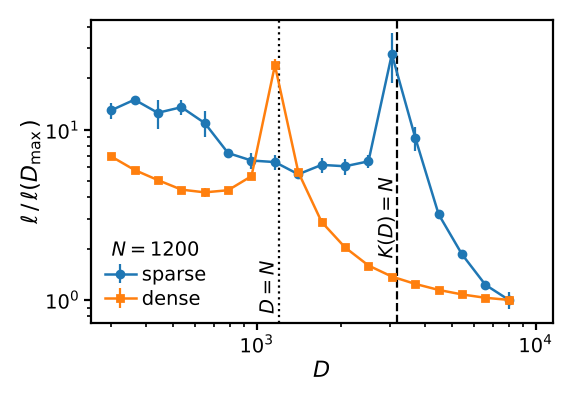

In [3]:
# FIGURE 5: loss vs D at N = 1200, sparse design and dense baseline

def make_peak_figure(N=1200):
    D_cov = Kinv(N)
    fig, ax = plt.subplots(figsize=(FIG_W, FIG_H), layout="constrained")
    for tag, color, fmt in (("sparse", "C0", "o-"), ("dense", "C1", "s-")):
        D, L, se = z[f"{N}_{tag}_D"], z[f"{N}_{tag}_L"], z[f"{N}_{tag}_se"]
        ax.errorbar(D, L / L[-1], se / L[-1], fmt=fmt, color=color, ms=2.5, lw=0.9,
                    elinewidth=0.8, capsize=0, label=tag)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(right=1.15e4)                      # so that 10^4 is labelled
    ax.axvline(N, ls=":", c="k", lw=0.8)
    ax.axvline(D_cov, ls="--", c="k", lw=0.8)
    blend = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
    ax.text(N, 0.03, "$D=N$", fontsize=FS_LEGEND, ha="right", va="bottom", rotation=90, transform=blend)
    ax.text(D_cov, 1.75, "$K(D)=N$", fontsize=FS_LEGEND, ha="right", va="bottom", rotation=90)
    ax.xaxis.set_minor_formatter(ticker.NullFormatter())
    ax.yaxis.set_minor_formatter(ticker.NullFormatter())
    ax.set_xlabel("$D$", fontsize=FS_LABEL, labelpad=1)
    ax.set_ylabel(r"$\ell\,/\,\ell(D_{\max})$", fontsize=FS_LABEL, labelpad=1)
    ax.tick_params(which="both", labelsize=FS_TICK, pad=1.5)
    ax.tick_params(which="major", length=2.5)
    ax.tick_params(which="minor", length=1.5)
    ax.legend(title=f"$N={N}$", loc="lower left", fontsize=FS_LEGEND, title_fontsize=FS_LEGEND,
              frameon=False, handletextpad=0.3, borderaxespad=0.3, labelspacing=0.25, handlelength=1.6)
    return fig


fig5 = make_peak_figure(1200)
fig5.savefig("figures/Figure5.pdf")
fig5.savefig("figures/Figure5.png", dpi=300)
plt.show()